In [ ]:
import sys
import os
sys.path.append(os.path.abspath(".."))
import matplotlib.pyplot as plt
import pandas as pd
from tests.datasets import load_dataset
from core.model_scores import generate_forecasts
from core.methods import KrichevskyTrofimov, UniversalPortfolio, DynamicallyTunedAdaptiveConformalInference
from core.runner import run_test

Importing plotly failed. Interactive plots will not work.
The StatsForecast module could not be imported. To enable support for the AutoARIMA, AutoETS and Croston models, please consider installing it.
The `XGBoost` module could not be imported. To enable XGBoost support in Darts, follow the detailed instructions in the installation guide: https://github.com/unit8co/darts/blob/master/INSTALL.md
The `XGBoost` module could not be imported. To enable XGBoost support in Darts, follow the detailed instructions in the installation guide: https://github.com/unit8co/darts/blob/master/INSTALL.md


In [5]:
data_name = "elec2"
data = load_dataset(data_name)
data

FileNotFoundError: [Errno 2] No such file or directory: './datasets/raw/elec2.csv'

In [4]:
model_name = "ar"
overwrite = False
log = False
fit_every = 1
ahead = 1
save_name = "../datasets/processed/" + data_name + "/" + model_name + "-" + str(fit_every) + "-steps" + ".npz"
forecasts = generate_forecasts(data, model_name, save_name, overwrite, log, fit_every, ahead)

Generating forecasts...


historical forecasts:   0%|          | 0/2990 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [8]:
if 'forecasts' not in data.columns:
    data['forecasts'] = forecasts
if 'scores' not in data.columns:
    data['scores'] = abs(data['y'] - data['forecasts'])

In [11]:
data['scores'].values

array([0.439155  , 0.415055  , 0.385004  , ..., 0.00431473, 0.01472391,
       0.02335491])

In [18]:
KT = KrichevskyTrofimov(alpha=0.05)
UP = UniversalPortfolio(alpha=0.05)
DTACI = DynamicallyTunedAdaptiveConformalInference(alpha=0.05)
KT_result = run_test(data['scores'].values, KT) 
UP_result = run_test(data['scores'].values, UP)
DTACI_result = run_test(data['scores'].values, DTACI)

In [61]:
KT_coverages = pd.Series(KT_result['coverages']).rolling(window=100, min_periods=1).mean().to_numpy()
UP_coverages = pd.Series(UP_result['coverages']).rolling(window=100, min_periods=1).mean().to_numpy()
DTACI_coverages = pd.Series(DTACI_result['coverages']).rolling(window=100, min_periods=1).mean().to_numpy()

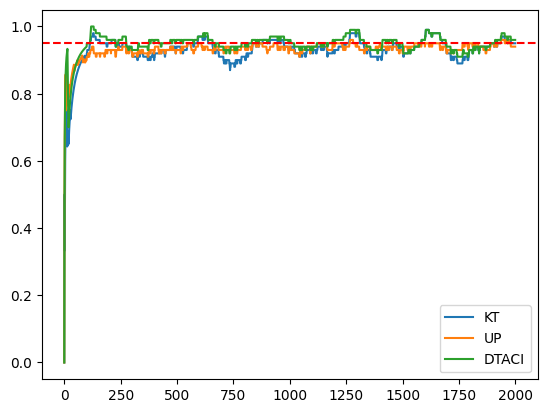

In [62]:
plt.plot(KT_coverages, label='KT')
plt.plot(UP_coverages, label='UP')
plt.plot(DTACI_coverages, label='DTACI')
plt.axhline(y=0.95, color='r', linestyle='--')
plt.legend()

In [63]:
for i in range(len(KT_coverages)):
    print(f"{i}\t{KT_coverages[i]:.4f}\t{UP_coverages[i]:.4f}\t{DTACI_coverages[i]:.4f}")

0	0.0000	0.0000	0.0000
1	0.5000	0.5000	0.5000
2	0.3333	0.6667	0.6667
3	0.5000	0.7500	0.7500
4	0.6000	0.8000	0.8000
5	0.6667	0.8333	0.8333
6	0.7143	0.8571	0.8571
7	0.7500	0.7500	0.8750
8	0.7778	0.7778	0.8889
9	0.8000	0.8000	0.9000
10	0.7273	0.8182	0.9091
11	0.7500	0.8333	0.9167
12	0.6923	0.7692	0.9231
13	0.6429	0.7857	0.9286
14	0.6667	0.8000	0.9333
15	0.6875	0.8125	0.8750
16	0.6471	0.7647	0.8235
17	0.6667	0.7778	0.7778
18	0.6842	0.7895	0.7368
19	0.6500	0.8000	0.7000
20	0.6667	0.8095	0.7143
21	0.6818	0.8182	0.7273
22	0.6957	0.8261	0.7391
23	0.7083	0.7917	0.7500
24	0.7200	0.8000	0.7600
25	0.7308	0.8077	0.7692
26	0.7407	0.8148	0.7778
27	0.7500	0.8214	0.7857
28	0.7241	0.8276	0.7931
29	0.7333	0.8333	0.8000
30	0.7419	0.8387	0.8065
31	0.7500	0.8438	0.8125
32	0.7576	0.8485	0.8182
33	0.7647	0.8529	0.8235
34	0.7714	0.8571	0.8286
35	0.7778	0.8611	0.8333
36	0.7838	0.8649	0.8378
37	0.7895	0.8684	0.8421
38	0.7949	0.8718	0.8462
39	0.8000	0.8750	0.8500
40	0.8049	0.8780	0.8537
41	0.8095	0.8810	0.8571
42